## Business case
To predict loan should be approved or rejected based on given features

## Domain analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('loan_approved.csv')
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


## Basic checks

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [5]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [6]:
df = df.rename({'Loan_Status (Approved)':'Loan_Status'}, axis = 1)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [8]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [9]:
df.describe(include='O')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [10]:
df['Gender'].unique()

# Or
# df.Gender.unique()

array(['Male', 'Female', nan], dtype=object)

In [11]:
df.Dependents.unique()

array(['0', '1', '2', '3+', nan], dtype=object)

In [12]:
type(df.Dependents.unique())

numpy.ndarray

In [13]:
len(df['Gender'].unique())

3

In [14]:
df['Credit_History'].unique()

array([ 1.,  0., nan])

In [15]:
len(df['Credit_History'].unique())

3

In [16]:
len(df['ApplicantIncome'].unique())

505

In [17]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [18]:
for i in df:
    if len(df[i].unique()) <= 20:
        print(i, ":", df[i].unique())
        print()

Gender : ['Male' 'Female' nan]

Married : ['No' 'Yes' nan]

Dependents : ['0' '1' '2' '3+' nan]

Education : ['Graduate' 'Not Graduate']

Self_Employed : ['No' 'Yes' nan]

Loan_Amount_Term : [360. 120. 240.  nan 180.  60. 300. 480.  36.  84.  12.]

Credit_History : [ 1.  0. nan]

Property_Area : ['Urban' 'Rural' 'Semiurban']

Loan_Status : ['Y' 'N']



In [19]:
df.Gender.value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [20]:
for i in df:
    if len(df[i].unique()) <= 20:
        print(df[i].value_counts())
        print('===============================')

Gender
Male      489
Female    112
Name: count, dtype: int64
Married
Yes    398
No     213
Name: count, dtype: int64
Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
Self_Employed
No     500
Yes     82
Name: count, dtype: int64
Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64
Credit_History
1.0    475
0.0     89
Name: count, dtype: int64
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
Loan_Status
Y    422
N    192
Name: count, dtype: int64


## EDA

In [21]:
df = df.drop('Loan_ID', axis = 1)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### Univariate analysis

In [22]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [23]:
cat_col = []
for i in df:
    if len(df[i].unique()) <= 20:
        cat_col.append(i)

In [24]:
cat_col

['Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

In [25]:
df_cat = df[cat_col]
df_cat.head()

,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,360.0,1.0,Urban,Y


In [26]:
cont_col = []
for i in df:
    if len(df[i].unique()) > 20:
        cont_col.append(i)

In [27]:
cont_col

['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

In [28]:
df_cont = df[cont_col]
df_cont.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount
0,5849,0.0,NaN
1,4583,1508.0,128.0
2,3000,0.0,66.0
3,2583,2358.0,120.0
4,6000,0.0,141.0


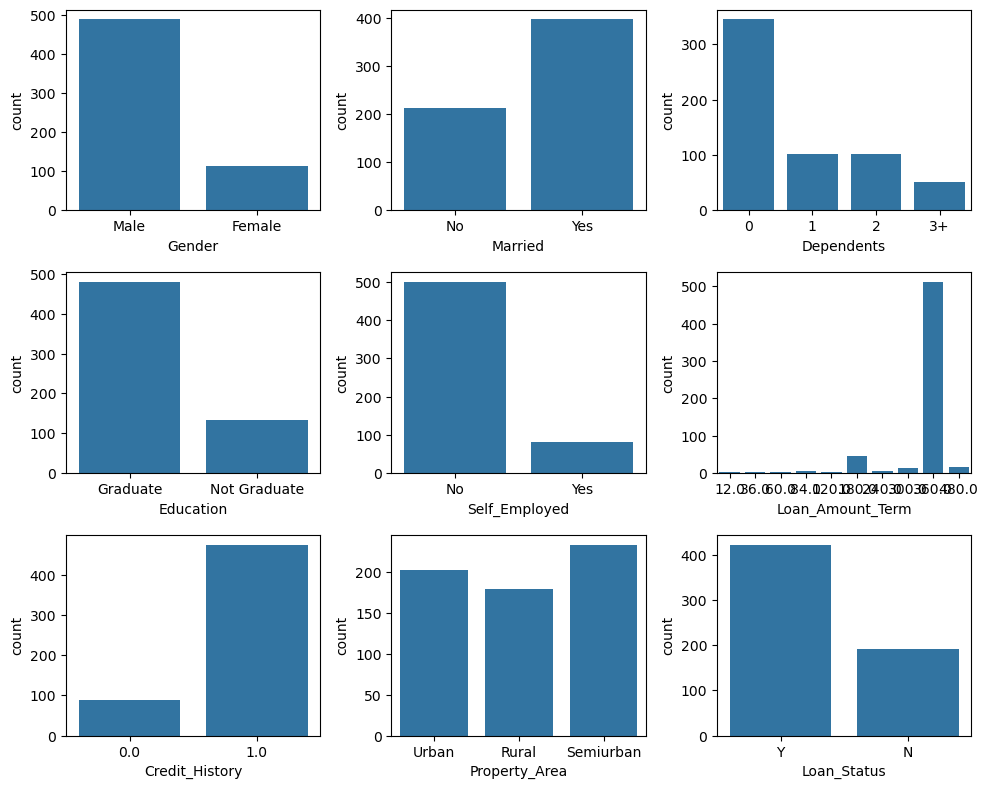

In [29]:
plt.figure(figsize=(10,8))
plotnumber = 1
for i in df_cat:
    plt.subplot(3,3,plotnumber)
    sns.countplot(x = df[i])
    plotnumber = plotnumber+1
plt.tight_layout()

Insights

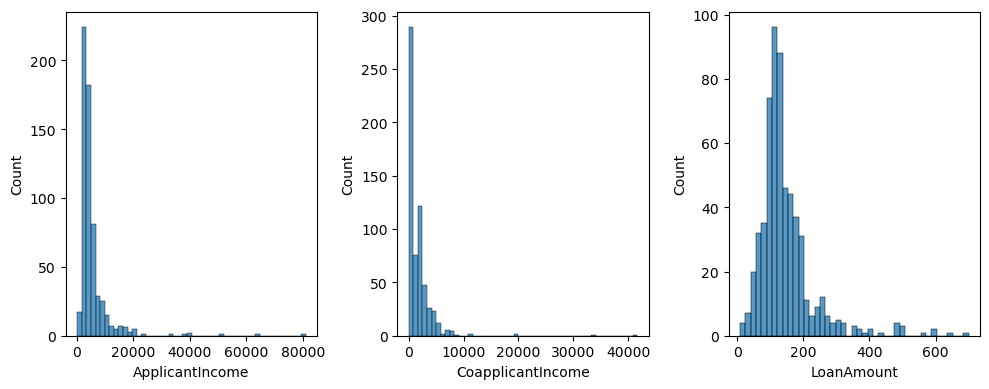

In [30]:
plt.figure(figsize=(10,4))
plotnumber = 1
for i in df_cont:
    plt.subplot(1,3,plotnumber)
    sns.histplot(x = df[i])
    plotnumber = plotnumber+1
plt.tight_layout()

Insights

### Bivariate analysis

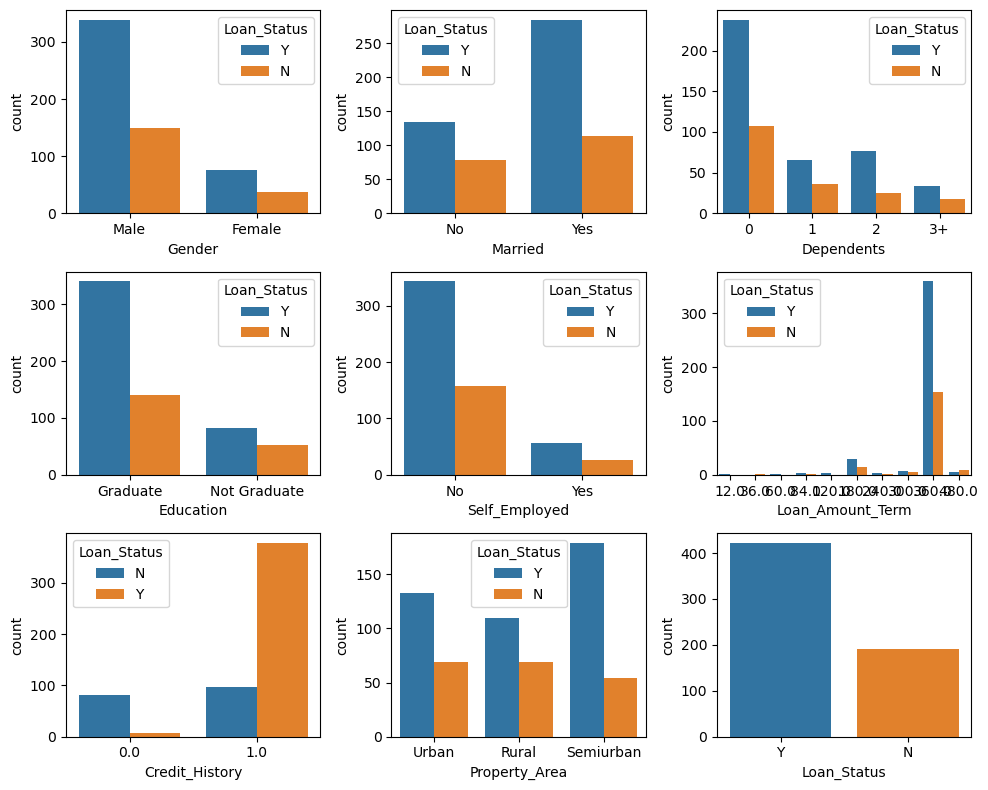

In [31]:
plt.figure(figsize=(10,8))
plotnumber = 1
for i in df_cat:
    plt.subplot(3,3,plotnumber)
    sns.countplot(x = df[i], hue=df['Loan_Status'])
    plotnumber = plotnumber+1
plt.tight_layout()

Insights

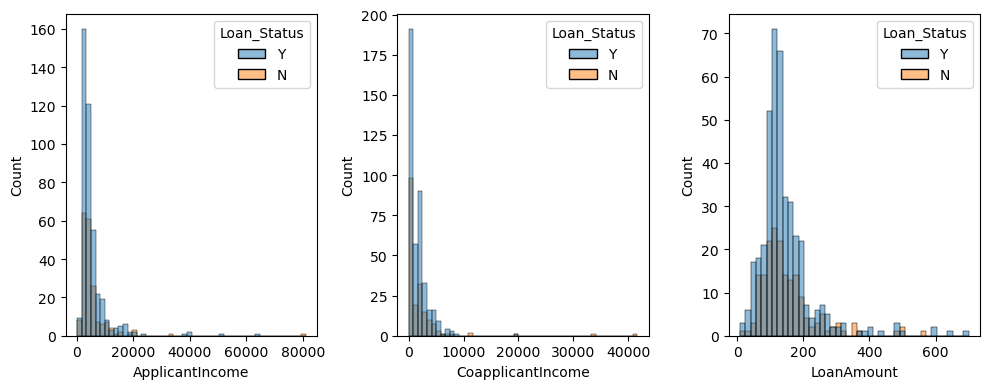

In [32]:
plt.figure(figsize=(10,4))
plotnumber = 1
for i in df_cont:
    plt.subplot(1,3,plotnumber)
    sns.histplot(x = df[i], hue = df['Loan_Status'])
    plotnumber = plotnumber+1
plt.tight_layout()

Insights

## Data preprocessing

#### Handling with null values

In [33]:
df.isnull().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [34]:
df.loc[df.Gender.isnull()]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
23,NaN,Yes,2,Not Graduate,No,3365,1917.0,112.0,360.0,0.0,Rural,N
126,NaN,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y
171,NaN,Yes,3+,Graduate,No,51763,0.0,700.0,300.0,1.0,Urban,Y
188,NaN,Yes,0,Graduate,Yes,674,5296.0,168.0,360.0,1.0,Rural,Y
314,NaN,Yes,0,Graduate,No,2473,1843.0,159.0,360.0,1.0,Rural,N
334,NaN,Yes,1,Graduate,Yes,9833,1833.0,182.0,180.0,1.0,Urban,Y
460,NaN,Yes,0,Graduate,Yes,2083,4083.0,160.0,360.0,NaN,Semiurban,Y
467,NaN,Yes,0,Graduate,No,16692,0.0,110.0,360.0,1.0,Semiurban,Y
477,NaN,Yes,2,Graduate,No,2873,1872.0,132.0,360.0,0.0,Semiurban,N
507,NaN,No,0,Graduate,No,3583,0.0,96.0,360.0,1.0,Urban,N


In [35]:
df.Gender.value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [36]:
df.loc[df.Gender.isnull(), 'Gender'] = 'Male'

In [37]:
df.loc[[23, 126]]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
23,Male,Yes,2,Not Graduate,No,3365,1917.0,112.0,360.0,0.0,Rural,N
126,Male,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y


In [38]:
df.Married.value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [39]:
df.loc[df.Married.isnull(), 'Married'] = 'Yes'

In [40]:
df.loc[df.Dependents.isnull()]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
102,Male,Yes,NaN,Graduate,No,13650,0.0,NaN,360.0,1.0,Urban,Y
104,Male,Yes,NaN,Graduate,No,3816,754.0,160.0,360.0,1.0,Urban,Y
120,Male,Yes,NaN,Graduate,No,5667,2667.0,180.0,360.0,1.0,Rural,Y
226,Male,Yes,NaN,Not Graduate,Yes,4735,0.0,138.0,360.0,1.0,Urban,N
228,Male,Yes,NaN,Graduate,No,4758,0.0,158.0,480.0,1.0,Semiurban,Y
293,Female,No,NaN,Graduate,No,5417,0.0,143.0,480.0,0.0,Urban,N
301,Male,Yes,NaN,Not Graduate,No,2875,1750.0,105.0,360.0,1.0,Semiurban,Y
332,Male,No,NaN,Graduate,No,2833,0.0,71.0,360.0,1.0,Urban,Y
335,Male,Yes,NaN,Graduate,Yes,5503,4490.0,70.0,NaN,1.0,Semiurban,Y
346,Male,Yes,NaN,Not Graduate,No,3523,3230.0,152.0,360.0,0.0,Rural,N


In [41]:
df.Dependents.value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [42]:
df.loc[df.Dependents.isnull(), 'Dependents'] = '0'

In [43]:
df.Dependents.value_counts()

Dependents
0     360
1     102
2     101
3+     51
Name: count, dtype: int64

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    object 
 1   Married            614 non-null    object 
 2   Dependents         614 non-null    object 
 3   Education          614 non-null    object 
 4   Self_Employed      582 non-null    object 
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    object 
 11  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 57.7+ KB


In [45]:
df.Self_Employed.value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [46]:
df.Self_Employed = df.Self_Employed.fillna(value='No')

In [47]:
df.LoanAmount

0        NaN
1      128.0
2       66.0
3      120.0
4      141.0
       ...  
609     71.0
610     40.0
611    253.0
612    187.0
613    133.0
Name: LoanAmount, Length: 614, dtype: float64

In [48]:
df.LoanAmount.dropna()

1      128.0
2       66.0
3      120.0
4      141.0
5      267.0
       ...  
609     71.0
610     40.0
611    253.0
612    187.0
613    133.0
Name: LoanAmount, Length: 592, dtype: float64

In [49]:
np.median(df.LoanAmount.dropna())

np.float64(128.0)

In [50]:
df.LoanAmount = df.LoanAmount.fillna(value = np.median(df.LoanAmount.dropna()))

In [51]:
df.Loan_Amount_Term.value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [52]:
df.Loan_Amount_Term = df.Loan_Amount_Term.fillna(value = 360.0)

In [53]:
df.Credit_History.value_counts()

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [54]:
df.Credit_History = df.Credit_History.fillna(value = 1.0)

# Or
# df.loc[df.Credit_History.isnull(), 'Credit_History'] = 1.0

In [55]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [56]:
# Handling with outlier

### Handling with categorical data

In [57]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [58]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [59]:
le.fit_transform(df.Gender)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1,

In [60]:
df.Gender = le.fit_transform(df.Gender)

In [61]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,1,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,1,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,1,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,1,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [62]:
df.Married = le.fit_transform(df.Married)
df.Dependents = le.fit_transform(df.Dependents)
df.Education = le.fit_transform(df.Education)
df.Self_Employed = le.fit_transform(df.Self_Employed)
df.Property_Area = le.fit_transform(df.Property_Area)
df.Loan_Status = le.fit_transform(df.Loan_Status)

In [63]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


In [64]:
df.Dependents.value_counts()

Dependents
0    360
1    102
2    101
3     51
Name: count, dtype: int64

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    int64  
 1   Married            614 non-null    int64  
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    int64  
 4   Self_Employed      614 non-null    int64  
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    int64  
 11  Loan_Status        614 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 57.7 KB


### Scaling

In [66]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


In [67]:
from sklearn.preprocessing import MinMaxScaler
ms = MinMaxScaler()

In [68]:
df.ApplicantIncome = ms.fit_transform(df[['ApplicantIncome']])             #2d

In [69]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,0.070489,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,0.054830,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,0.035250,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,0.030093,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,0.072356,0.0,141.0,360.0,1.0,2,1


In [70]:
df.CoapplicantIncome = ms.fit_transform(df[['CoapplicantIncome']])  
df.LoanAmount = ms.fit_transform(df[['LoanAmount']])  
df.Loan_Amount_Term = ms.fit_transform(df[['Loan_Amount_Term']])  

In [71]:
a = 2
b = 3
c = 4

In [72]:
a, b, c = 2, 3, 4

In [73]:
# Or
# df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']] = ms.fit_transform(df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']])

In [74]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,0.070489,0.000000,0.172214,0.74359,1.0,2,1
1,1,1,1,0,0,0.054830,0.036192,0.172214,0.74359,1.0,0,0
2,1,1,0,0,1,0.035250,0.000000,0.082489,0.74359,1.0,2,1
3,1,1,0,1,0,0.030093,0.056592,0.160637,0.74359,1.0,2,1
4,1,0,0,0,0,0.072356,0.000000,0.191027,0.74359,1.0,2,1


## Feature selection

In [75]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,0.070489,0.000000,0.172214,0.74359,1.0,2,1
1,1,1,1,0,0,0.054830,0.036192,0.172214,0.74359,1.0,0,0
2,1,1,0,0,1,0.035250,0.000000,0.082489,0.74359,1.0,2,1
3,1,1,0,1,0,0.030093,0.056592,0.160637,0.74359,1.0,2,1
4,1,0,0,0,0,0.072356,0.000000,0.191027,0.74359,1.0,2,1


In [76]:
df.corr()         #check only for continuos column

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Gender,1.000000,0.364569,0.172914,0.045364,-0.000525,0.058809,0.082912,0.106904,-0.074030,0.009170,-0.025752,0.017987
Married,0.364569,1.000000,0.334216,0.012304,0.004489,0.051708,0.075948,0.146546,-0.100912,0.010938,0.004257,0.091478
Dependents,0.172914,0.334216,1.000000,0.055752,0.056798,0.118202,0.030430,0.163103,-0.103864,-0.040160,-0.000244,0.010118
Education,0.045364,0.012304,0.055752,1.000000,-0.010383,-0.140760,-0.062290,-0.168759,-0.073928,-0.073658,-0.065243,-0.085884
Self_Employed,-0.000525,0.004489,0.056798,-0.010383,1.000000,0.127180,-0.016100,0.115100,-0.033739,-0.001550,-0.030860,-0.003700
ApplicantIncome,0.058809,0.051708,0.118202,-0.140760,0.127180,1.000000,-0.116605,0.565181,-0.046531,-0.018615,-0.009500,-0.004710
CoapplicantIncome,0.082912,0.075948,0.030430,-0.062290,-0.016100,-0.116605,1.000000,0.189218,-0.059383,0.011134,0.010522,-0.059187
LoanAmount,0.106904,0.146546,0.163103,-0.168759,0.115100,0.565181,0.189218,1.000000,0.036960,-0.000607,-0.046632,-0.033214
Loan_Amount_Term,-0.074030,-0.100912,-0.103864,-0.073928,-0.033739,-0.046531,-0.059383,0.036960,1.000000,-0.004705,-0.076120,-0.022549
Credit_History,0.009170,0.010938,-0.040160,-0.073658,-0.001550,-0.018615,0.011134,-0.000607,-0.004705,1.000000,0.001963,0.540556


<Axes: >

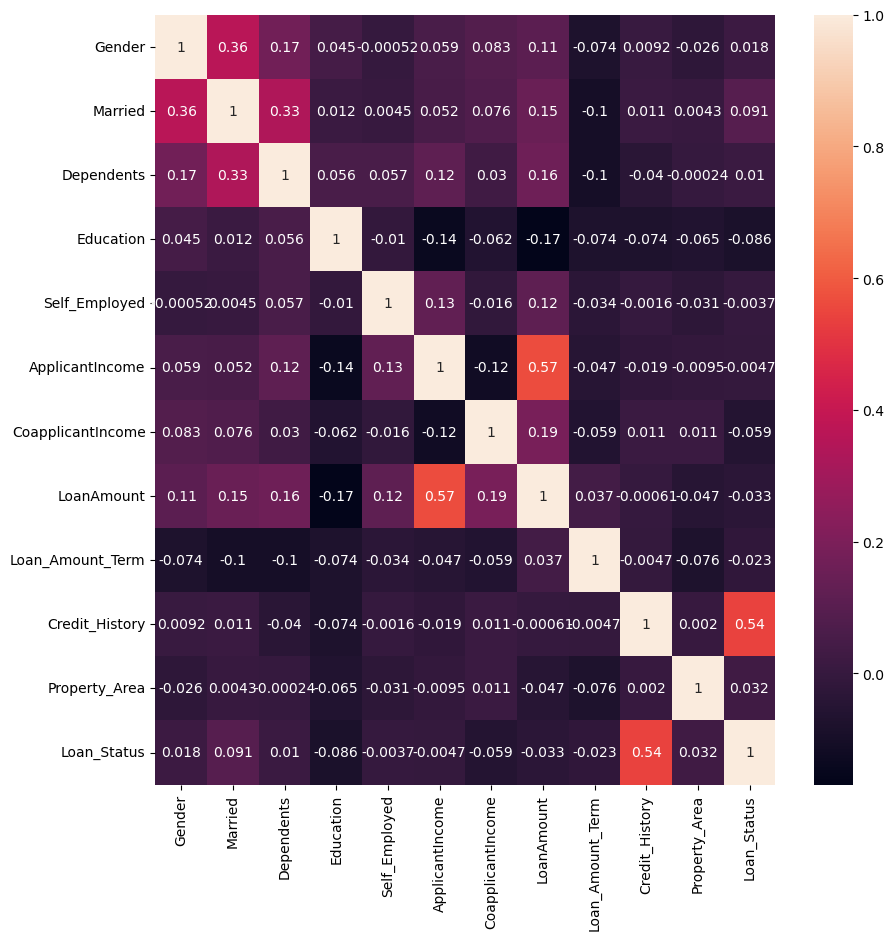

In [77]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True)       

## Model creation

In [78]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,0.070489,0.000000,0.172214,0.74359,1.0,2,1
1,1,1,1,0,0,0.054830,0.036192,0.172214,0.74359,1.0,0,0
2,1,1,0,0,1,0.035250,0.000000,0.082489,0.74359,1.0,2,1
3,1,1,0,1,0,0.030093,0.056592,0.160637,0.74359,1.0,2,1
4,1,0,0,0,0,0.072356,0.000000,0.191027,0.74359,1.0,2,1


In [79]:
x = df.drop('Loan_Status', axis = 1)
x

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,1,0,0,0,0,0.070489,0.000000,0.172214,0.743590,1.0,2
1,1,1,1,0,0,0.054830,0.036192,0.172214,0.743590,1.0,0
2,1,1,0,0,1,0.035250,0.000000,0.082489,0.743590,1.0,2
3,1,1,0,1,0,0.030093,0.056592,0.160637,0.743590,1.0,2
4,1,0,0,0,0,0.072356,0.000000,0.191027,0.743590,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,0.034014,0.000000,0.089725,0.743590,1.0,0
610,1,1,3,0,0,0.048930,0.000000,0.044863,0.358974,1.0,0
611,1,1,1,0,0,0.097984,0.005760,0.353111,0.743590,1.0,2
612,1,1,2,0,0,0.091936,0.000000,0.257598,0.743590,1.0,2


In [80]:
y = df.Loan_Status
y

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

In [81]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=48)

In [82]:
x_train

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
101,1,0,0,0,0,0.058046,0.091343,0.205499,0.74359,1.0,1
516,0,1,2,0,0,0.023265,0.039168,0.150507,1.00000,1.0,1
488,1,1,2,0,1,0.054830,0.049992,0.218524,0.74359,1.0,1
81,1,1,1,0,1,0.027767,0.000000,0.172214,0.74359,1.0,1
329,0,0,0,0,0,0.029066,0.000000,0.083936,0.74359,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
347,1,1,2,1,0,0.036277,0.052032,0.169320,0.74359,1.0,2
452,1,1,0,0,0,0.046976,0.041592,0.202605,0.74359,0.0,0
337,1,1,2,0,1,0.029066,0.110399,0.241679,0.74359,1.0,0
563,1,0,0,1,1,0.069882,0.000000,0.178003,0.74359,1.0,1


In [83]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(460, 11)
(460,)
(154, 11)
(154,)


In [84]:
y.value_counts()

Loan_Status
1    422
0    192
Name: count, dtype: int64

In [85]:
from imblearn.over_sampling import SMOTE
sm = SMOTE()

In [86]:
x_sm, y_sm = sm.fit_resample(x_train, y_train)

In [87]:
y_train.value_counts()

Loan_Status
1    319
0    141
Name: count, dtype: int64

In [88]:
y_sm.value_counts()

Loan_Status
1    319
0    319
Name: count, dtype: int64

In [89]:
from collections import Counter
print(Counter(y_train))
print(Counter(y_sm))

Counter({1: 319, 0: 141})
Counter({1: 319, 0: 319})


In [90]:
from sklearn.svm import SVC
sv = SVC()

In [91]:
sv.fit(x_sm, y_sm)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [92]:
y_pred = sv.predict(x_test)
y_pred

array([1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1])

In [93]:
np.array(y_test)

array([1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0])

## Model evaluation

In [94]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

In [95]:
accuracy_score(y_test, y_pred)

0.7467532467532467

In [96]:
precision_score(y_test, y_pred)

0.7352941176470589

In [97]:
recall_score(y_test, y_pred)

0.970873786407767

In [98]:
f1_score(y_test, y_pred)

0.8368200836820083

In [99]:
roc_auc_score(y_test, y_pred)

0.6324957167332952

In [100]:
confusion_matrix(y_test, y_pred)

array([[ 15,  36],
       [  3, 100]])

In [101]:
pd.crosstab(y_test, y_pred)

col_0,0,1
Loan_Status,,
0,15,36
1,3,100


In [102]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.29      0.43        51
           1       0.74      0.97      0.84       103

    accuracy                           0.75       154
   macro avg       0.78      0.63      0.64       154
weighted avg       0.77      0.75      0.70       154



### Cross validation

In [103]:
from sklearn.svm import SVC
sv1 = SVC()

In [104]:
from sklearn.model_selection import cross_val_score

In [105]:
cv_scores = cross_val_score(sv1, x, y, cv = 5, scoring = 'precision')
cv_scores

# scoring = 'accuracy'
# scoring = 'precision'
# scoring = 'recall'
# scoring = 'f1'

array([0.79245283, 0.76851852, 0.76635514, 0.83      , 0.79807692])

In [106]:
cv_scores.mean()

np.float64(0.7910806823942073)

In [107]:
cv_scores.std()

np.float64(0.023177347269948356)

## Hyperparameter tuning

In [ ]:
def add1(a,b):
    return a+b

In [ ]:
add1(5, 3)

In [ ]:
def add(a=10,b=5):
    return a+b

In [ ]:
add(a=16,b=32)

In [ ]:
add()

In [ ]:
add(a=12)

In [ ]:
add(b=2)

In [ ]:
# c and gamma -----> hyperparmeters
# c = [0.1, 1, 10, 100, 1000]
# gamma = [1, 0.1, 0.01, 0.001, 0.0001]

In [108]:
from sklearn.svm import SVC
sv2 = SVC()

In [109]:
from sklearn.model_selection import GridSearchCV

In [110]:
param_grid = {'C' : [0.1, 1, 10, 100, 1000], 'gamma' : [1, 0.1, 0.01, 0.001, 0.0001]}

In [130]:
grid = GridSearchCV(sv2, param_grid, scoring = 'precision', verbose=3, cv = 5)
grid

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...]}"
,scoring,'precision'
,n_jobs,None
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1.0


In [131]:
grid.fit(x,y)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ....................C=0.1, gamma=1;, score=0.691 total time=   0.0s
[CV 2/5] END ....................C=0.1, gamma=1;, score=0.691 total time=   0.0s
[CV 3/5] END ....................C=0.1, gamma=1;, score=0.683 total time=   0.0s
[CV 4/5] END ....................C=0.1, gamma=1;, score=0.683 total time=   0.0s
[CV 5/5] END ....................C=0.1, gamma=1;, score=0.689 total time=   0.0s
[CV 1/5] END ..................C=0.1, gamma=0.1;, score=0.691 total time=   0.0s
[CV 2/5] END ..................C=0.1, gamma=0.1;, score=0.691 total time=   0.0s
[CV 3/5] END ..................C=0.1, gamma=0.1;, score=0.683 total time=   0.0s
[CV 4/5] END ..................C=0.1, gamma=0.1;, score=0.683 total time=   0.0s
[CV 5/5] END ..................C=0.1, gamma=0.1;, score=0.689 total time=   0.0s
[CV 1/5] END .................C=0.1, gamma=0.01;, score=0.691 total time=   0.0s
[CV 2/5] END .................C=0.1, gamma=0.01

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...]}"
,scoring,'precision'
,n_jobs,None
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [132]:
grid.best_params_

{'C': 1, 'gamma': 0.1}

In [123]:
grid.best_estimator_

,C,1
,kernel,'rbf'
,degree,3
,gamma,0.1
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [125]:
sv3 = SVC(C = 1, gamma = 0.1)

In [126]:
sv3.fit(x_sm, y_sm)

,C,1
,kernel,'rbf'
,degree,3
,gamma,0.1
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [128]:
y_pred1 = sv3.predict(x_test)
y_pred1

array([1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1])

In [129]:
np.array(y_test)

array([1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0])

In [138]:
accuracy_score(y_test, y_pred1)

0.7402597402597403

In [134]:
precision_score(y_test, y_pred1)

0.7266187050359713

In [136]:
cv_scores1 = cross_val_score(sv3, x, y, cv = 5, scoring = 'precision')
cv_scores1

array([0.79245283, 0.76851852, 0.76635514, 0.83      , 0.79807692])

In [137]:
cv_scores1.mean()

np.float64(0.7910806823942073)